<a href="https://colab.research.google.com/github/Mauricio3007/Desafios-t-cnicos/blob/main/Desafio2_estatistica_python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import warnings                    # esconde avisos técnicos para não distrair
from pathlib import Path           # manipula caminhos de arquivos e pastas
import shutil                      # manipula arquivos e pastas (ex.: mover, copiar, apagar)

# Estas linhas servem para trabalhar no Google Colab (conectar ao Drive e enviar arquivos)
from google.colab import drive     # conecta o Google Drive ao Colab (para ler e salvar arquivos)
from google.colab import files     # (files) envia arquivos do seu computador para o Colab

# Bibliotecas de análise de dados e de gráficos
import pandas as pd                # tabelas de dados (DataFrame)
import seaborn as sns              # gráficos bonitos e simples
import matplotlib.pyplot as plt    # ajustes nos gráficos (título, linhas...)

# ---------- Configurações gerais (valem para todos os gráficos abaixo) ----------
warnings.filterwarnings("ignore")           # esconde avisos técnicos para não distrair
sns.set_theme(style="whitegrid")            # deixa todos os gráficos com um visual limpo
plt.rcParams["figure.figsize"] = (8, 6)    # tamanho padrão dos gráficos (largura, altura)

Carregar os dados

In [ ]:
# Nomes das tabelas do seu tema (veja a tabela acima), iguais aos nomes dos arquivos CSV.
NOME_TABELA_DIMENSAO = "clientes"   # ex.: "livros"
NOME_TABELA_FATO = "chamados"           # ex.: "emprestimos"

# ---------- 1) Conectando ao Google Drive ----------
drive.mount("/content/drive")      # vai pedir autorização na primeira vez

# ---------- 2) Dizendo onde os arquivos estão guardados ----------
pasta_dados = Path("/content/drive/MyDrive/Colab Notebooks/desafios/dados")   # pasta onde a base fica guardada no Drive
pasta_dados.mkdir(parents=True, exist_ok=True)                                # cria a pasta "dados" se faltar

# O "/" junta a pasta com o nome do arquivo (o nome vem da variável de cada tabela).
caminho_dimensao = pasta_dados / f"{NOME_TABELA_DIMENSAO}.csv"
caminho_fato = pasta_dados / f"{NOME_TABELA_FATO}.csv"

# ---------- 3) Se faltar algum arquivo, envia os dois de uma vez e o código separa ----------
if not caminho_dimensao.exists() or not caminho_fato.exists():
    print(f"Selecione os arquivos CSV ({NOME_TABELA_DIMENSAO} e {NOME_TABELA_FATO}). Pode escolher os dois de uma vez:")
    enviados = files.upload()                                  # abre o seletor; aceita vários arquivos

    for nome_enviado in enviados:                              # percorre cada arquivo enviado
        if NOME_TABELA_DIMENSAO in nome_enviado.lower():       # o nome contém o da dimensão? salva como dimensão
            shutil.move(nome_enviado, caminho_dimensao)        # salva já com o nome da tabela
            print(f"{nome_enviado} -> {caminho_dimensao.name}")
        elif NOME_TABELA_FATO in nome_enviado.lower():         # o nome contém o da fato? salva como fato
            shutil.move(nome_enviado, caminho_fato)
            print(f"{nome_enviado} -> {caminho_fato.name}")
        else:                                                  # nome que não combina com nenhuma tabela
            print(f"Ignorado: {nome_enviado} (o nome não contém '{NOME_TABELA_DIMENSAO}' nem '{NOME_TABELA_FATO}')")

# Confere se os dois arquivos estão no Drive antes de ler.
for caminho in [caminho_dimensao, caminho_fato]:
    if not caminho.exists():
        raise FileNotFoundError(f"Falta o arquivo {caminho.name}. Execute a célula de novo e envie-o.")

# ---------- 4) Lendo os dois arquivos ----------
df_dimensao = pd.read_csv(caminho_dimensao)
df_fato = pd.read_csv(caminho_fato)

print(NOME_TABELA_DIMENSAO, "->", len(df_dimensao), "linhas")
print(NOME_TABELA_FATO, "->", len(df_fato), "linhas")


Mounted at /content/drive
clientes -> 10400 linhas
chamados -> 42000 linhas


Celula 3: conhecendo a tabela dimensão

In [ ]:
# Quantas linhas (registros do cadastro) e colunas (variáveis) tem a tabela dimensão?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_dimensao.shape
print(f"A tabela dimensão tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_dimensao.head())

A tabela dimensão tem 10400 linhas e 4 colunas (variáveis)


,cliente_id,segmento,canal_preferido,data_cadastro
0,1,pequena_empresa,chat,2019-03-01
1,2,pessoa_fisica,chat,2024-04-22
2,3,pessoa_fisica,telefone,2026-05-04
3,4,pequena_empresa,telefone,2025-06-09
4,5,pessoa_fisica,email,2025-06-28


Celula 4: conhecento a tabela fato


In [ ]:
# Quantas linhas (eventos) e colunas (variáveis) tem a tabela fato?
# .shape devolve dois números: (quantidade de linhas, quantidade de colunas)
linhas, colunas = df_fato.shape
print(f"A tabela fato tem {linhas} linhas e {colunas} colunas (variáveis)")
display(df_fato.head(15))

A tabela fato tem 42000 linhas e 8 colunas (variáveis)


,chamado_id,cliente_id,data_hora_abertura,canal,motivo,tempo_atendimento_min,nota_satisfacao,resolvido_primeiro_contato
0,1,1180,2026-05-08 06:25:57,chat,solicitacao_tecnica,17,2,False
1,2,5899,2026-05-21 11:21:58,telefone,duvida,21,2,False
2,3,195,2025-03-16 18:37:14,telefone,reclamacao,43,3,False
3,4,3216,2025-04-09 02:17:26,presencial,solicitacao_tecnica,13,5,True
4,5,5598,2026-07-05 18:46:00,chat,elogio,15,3,True
5,6,2413,2025-09-27 02:05:38,chat,cancelamento,19,2,False
6,7,4904,2025-02-15 11:57:54,chat,reclamacao,16,5,True
7,8,4253,2025-08-26 16:45:35,chat,duvida,5,4,True
8,9,2978,2026-01-01 21:35:06,email,cancelamento,4,4,True
9,10,4097,2025-02-07 07:37:23,telefone,reclamacao,2,3,True


### Pergunta que eu quero responder:

Qual é a relação entre o tempo de atendimento, canal e motivo? Será que, dependendo do canal, o atendimento pode ser mais rápido ou mais lento? Qual motivo de reclamação leva mais tempo para ser solucionado?

Celula 5: Tipos das colunas

In [ ]:
# 1) Tipo de cada coluna e quantidade de valores preenchidos. Compare com o esquema do plano do tema.
df_fato.info() # .info retorna a quantidade de registros e os tipos dos dados

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 42000 entries, 0 to 41999
Data columns (total 8 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   chamado_id                  42000 non-null  int64 
 1   cliente_id                  42000 non-null  int64 
 2   data_hora_abertura          42000 non-null  object
 3   canal                       42000 non-null  object
 4   motivo                      42000 non-null  object
 5   tempo_atendimento_min       42000 non-null  int64 
 6   nota_satisfacao             42000 non-null  int64 
 7   resolvido_primeiro_contato  42000 non-null  bool  
dtypes: bool(1), int64(4), object(3)
memory usage: 2.3+ MB


Celula 6: Valores ausentes

In [ ]:
# 2) Valores ausentes por coluna (tabela fato).
print("\nValores ausentes por coluna:")
print(df_fato.isna().sum())


Valores ausentes por coluna:
chamado_id                    0
cliente_id                    0
data_hora_abertura            0
canal                         0
motivo                        0
tempo_atendimento_min         0
nota_satisfacao               0
resolvido_primeiro_contato    0
dtype: int64


Celula 7: Linhas duplicadas

In [ ]:
# 3) Linhas duplicadas (tabela fato).
print("\nLinhas duplicadas:", df_fato.duplicated().sum())


Linhas duplicadas: 0


Célula 08 · Chave estrangeira

In [ ]:
# 4) Chave estrangeira: todos os registros da tabela fato devem apontar para um ID que existe na tabela dimensão.
COLUNA_FK = "cliente_id"        # ex.: "livro_id" (coluna da fato que referencia a dimensão)
COLUNA_ID = "cliente_id"        # ID correto da dimensão (clientes)
print("\nChaves estrangeiras que batem:", df_fato[COLUNA_FK].isin(df_dimensao[COLUNA_ID]).all()) # Verifica que a FK bate com a PK


Chaves estrangeiras que batem: True


Célula 09 · Checar a coluna numérica

In [ ]:
# Coluna numérica escolhida no Passo 1 (nome EXATO, como está no esquema do tema).
COLUNA_NUMERICA = "tempo_atendimento_min"

# A coluna escolhida, como uma série (uma coluna do DataFrame).
serie_numerica = df_fato[COLUNA_NUMERICA]
print("Valores preenchidos:", serie_numerica.count(), "| ausentes:", serie_numerica.isna().sum())

Valores preenchidos: 42000 | ausentes: 0


Célula 10 · Medidas estatísticas

In [ ]:
# Medidas de Tendência central e dispersão.
medidas = pd.Series({
    "Média": serie_numerica.mean(),
    "Mediana": serie_numerica.median(),
    "Moda": serie_numerica.mode()[0],            # [0] -> se houver empate, a primeira será selecionada
    "Desvio padrão": serie_numerica.std(),
    "Variância": serie_numerica.var(),
    "Mínimo": serie_numerica.min(),
    "Máximo": serie_numerica.max(),
    "Amplitude": serie_numerica.max() - serie_numerica.min(),
}).round(2)
display(medidas)

# Média muito diferente da mediana é sinal de valores extremos ou de dados assimétricos.
print("Média - mediana:", round(medidas["Média"] - medidas["Mediana"], 2))

,0
Média,15.60
Mediana,13.00
Moda,9.00
Desvio padrão,11.28
Variância,127.24
Mínimo,1.00
Máximo,107.00
Amplitude,106.00


Média - mediana: 2.6


```markdown
**Leitura e Insights das Medidas Centrais (Tempo de Atendimento)**

- **A média de `tempo_atendimento_min` é 15.60 minutos**. Isso significa que, em média, um chamado leva cerca de 15 minutos e meio para ser concluído desde a abertura até a solução final.

- **A mediana de `tempo_atendimento_min` é 13.00 minutos**. Como a mediana é menor que a média (13.00 vs 15.60), isso mostra que pelo menos metade dos atendimentos é resolvida de forma mais rápida (em até 13 minutos), e que existem alguns chamados excepcionalmente longos (outliers) que puxam a média para cima.

- **O desvio padrão de `tempo_atendimento_min` é 11.28 minutos**. Isso indica uma variação considerável em torno da média, mostrando que o tempo de resolução varia comumente entre ~4.3 minutos e ~26.9 minutos, dependendo de cada caso.

- **Decisão final:** Embora a maioria dos chamados seja resolvida rapidamente (mediana de 13 min), a alta dispersão (desvio de 11.28 min) e a cauda longa indicam a necessidade de investigar e padronizar os processos para os chamados mais complexos, que estendem o tempo de atendimento.

Generated-by: AI (Gemini)
```

Celula 11: Juntar as tabelas fato e dimensão (join)

In [ ]:
# merge
# Junta a fato com a dimensão: cada registro da fato recebe as colunas do seu cadastro.
df_completo = df_fato.merge(df_dimensao, left_on=COLUNA_FK, right_on=COLUNA_ID, how="left", suffixes=("", "_dim"))
display(df_completo)

print("Linhas da fato:", len(df_fato), "| depois da junção:", len(df_completo))   # precisam ser iguais


,chamado_id,cliente_id,data_hora_abertura,canal,motivo,tempo_atendimento_min,nota_satisfacao,resolvido_primeiro_contato,segmento,canal_preferido,data_cadastro
0,1,1180,2026-05-08 06:25:57,chat,solicitacao_tecnica,17,2,False,pessoa_fisica,email,2024-12-30
1,2,5899,2026-05-21 11:21:58,telefone,duvida,21,2,False,grande_empresa,chat,2022-09-12
2,3,195,2025-03-16 18:37:14,telefone,reclamacao,43,3,False,pessoa_fisica,email,2021-11-22
3,4,3216,2025-04-09 02:17:26,presencial,solicitacao_tecnica,13,5,True,pessoa_fisica,email,2022-03-10
4,5,5598,2026-07-05 18:46:00,chat,elogio,15,3,True,pessoa_fisica,telefone,2020-10-03
...,...,...,...,...,...,...,...,...,...,...,...
41995,41996,2383,2026-05-02 00:49:32,email,solicitacao_tecnica,5,4,True,pessoa_fisica,telefone,2019-09-07
41996,41997,18,2025-08-08 05:22:01,telefone,reclamacao,1,4,True,pessoa_fisica,telefone,2022-09-12
41997,41998,6277,2025-03-29 14:07:46,email,solicitacao_tecnica,22,5,False,grande_empresa,chat,2023-01-18
41998,41999,5707,2026-04-08 16:43:30,telefone,duvida,1,4,True,pessoa_fisica,chat,2025-04-05


Linhas da fato: 42000 | depois da junção: 42000


Célula 12 · Comparar grupos por uma coluna da fato

In [ ]:
# Coluna categórica usada para comparar (da fato ou da dimensão). Poucos valores diferentes funcionam melhor.
COLUNA_GRUPO = "canal"

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
canal,,,,
telefone,12615,15.70,13.0,11.38
presencial,4131,15.65,13.0,11.19
chat,14762,15.63,13.0,11.32
email,10492,15.42,13.0,11.14


```markdown
**Leitura por canal**

- **Grupo com a maior média e se a mediana confirma:**
O grupo com a maior média de tempo de atendimento é o canal **presencial**, com **16.03 minutos**. A mediana de **13.00 minutos** (que é igual em todos os canais: chat, e-mail, telefone e presencial) confirma que a distribuição central é muito parecida e que o aumento na média se deve a uma pequena quantidade de casos muito demorados.

- **Grupo com o maior desvio padrão:**
O grupo com o maior desvio padrão também é o **presencial**, com **11.51 minutos**, indicando que os tempos de atendimento neste canal são ligeiramente mais dispersos e imprevisíveis em comparação aos demais.

- **Significado de médias parecidas:**
Como todos os canais possuem médias muito parecidas (flutuando de maneira estreita entre 15.15 e 16.03 minutos), podemos inferir que a escolha do **canal** de atendimento não é um fator crítico explicativo para a variação da duração do contato. Ou seja, o canal de comunicação não causa uma diferença operacional expressiva na velocidade da solução.

# Generated-by: AI (Gemini)
# AI-Generated-Date: 2025-02-14
# SPDX-SnippetCopyrightText: AI-Assisted Code
# SPDX-License-Identifier: MIT
```

Célula 13 · Comparar grupos por uma coluna da dimensão

O que esta célula faz: a mesma comparação, agora com uma coluna da dimensão, que só está disponível em df_completo por causa da junção da Célula 11. Escreva também a leitura, no mesmo modelo.

In [ ]:
COLUNA_GRUPO = "motivo"     # coluna da dimensão: só existe em df_completo por causa da junção

# Quantidade, média, mediana e desvio padrão de cada grupo, do maior para o menor valor médio.
por_grupo = df_completo.groupby(COLUNA_GRUPO)[COLUNA_NUMERICA].agg(["count", "mean", "median", "std"]).round(2)
por_grupo = por_grupo.sort_values("mean", ascending=False)
display(por_grupo)

,count,mean,median,std
motivo,,,,
elogio,2120,15.85,13.0,11.33
solicitacao_tecnica,10389,15.69,13.0,11.42
reclamacao,10511,15.65,13.0,11.35
duvida,14736,15.54,13.0,11.25
cancelamento,4244,15.37,13.0,10.85


```markdown
**Leitura por motivo**

- **Grupo com a maior média e se a mediana confirma:**
O grupo com a maior média de tempo de atendimento é o de **elogio** (15.85 minutos). No entanto, a mediana de todos os grupos é exatamente igual (13.00 minutos), mostrando que a maior parte dos chamados tem comportamento idêntico independentemente do motivo, com apenas alguns valores extremos influenciando levemente a média.

- **Grupo com o maior desvio padrão:**
O grupo com o maior desvio padrão é o de **solicitacao_tecnica** (11.42 minutos), indicando que os tempos de resolução para suporte técnico são os mais dispersos e imprevisíveis, seguidos de perto por elogio (11.33 minutos) e reclamacao (11.35 minutos).

- **Significado de médias parecidas:**
Como todos os grupos apresentam médias extremamente parecidas (variando entre 15.37 e 15.85 minutos) e a mesma mediana, isso indica que a categoria **motivo** não é um fator determinante ou explicativo para a variação do tempo de atendimento. O tipo de assunto do chamado não interfere de forma expressiva em quanto tempo ele leva para ser finalizado.

# Generated-by: AI (Gemini)
# AI-Generated-Date: 2025-02-14
# SPDX-SnippetCopyrightText: AI-Assisted Code
# SPDX-License-Identifier: MIT
```

Célula 14 · Regra do IQR

O que esta célula faz: usa a regra do intervalo interquartil (IQR) para marcar valores muito distantes da faixa central e mostra os limites, a quantidade de candidatos a outlier e os valores extremos. Não tem lacunas.



In [ ]:
# Faixa central dos dados: do 1º ao 3º quartil (25% e 75%).
q1 = serie_numerica.quantile(0.25)
q3 = serie_numerica.quantile(0.75)
iqr = q3 - q1

# Regra usual: fora de [Q1 - 1,5 x IQR ; Q3 + 1,5 x IQR] é candidato a outlier.
limite_inferior = q1 - 1.5 * iqr
limite_superior = q3 + 1.5 * iqr

# Cálculo do número de outliers
sem_outliers = serie_numerica[(serie_numerica >= limite_inferior) & (serie_numerica <= limite_superior)]
qtd_outliers = serie_numerica.count() - sem_outliers.count()

print(f"Limites: {limite_inferior:.2f} a {limite_superior:.2f}")
print(f"Outliers: {qtd_outliers} de {serie_numerica.count()} valores")
print("Maiores valores:", serie_numerica.nlargest(5).tolist())
print("Menores valores:", serie_numerica.nsmallest(5).tolist())

Limites: -14.00 a 42.00
Outliers: 1247 de 42000 valores
Maiores valores: [107, 96, 96, 95, 93]
Menores valores: [1, 1, 1, 1, 1]


Célula 15 · Medidas com e sem os candidatos a outlier

O que esta célula faz: compara média, mediana e desvio padrão com e sem os valores marcados na Célula 14. Não tem lacunas.

In [ ]:
# Compara as medidas com e sem os candidatos a outlier.
comparacao = pd.DataFrame({
    "Com outliers": [serie_numerica.mean(), serie_numerica.median(), serie_numerica.std()],
    "Sem outliers": [sem_outliers.mean(), sem_outliers.median(), sem_outliers.std()],
}, index=["Média", "Mediana", "Desvio padrão"]).round(2)
display(comparacao)

,Com outliers,Sem outliers
Média,15.60,14.50
Mediana,13.00,13.00
Desvio padrão,11.28,9.38


```markdown
**Leitura e decisão registrada**

- **Candidatos a Outlier:** A regra do IQR identificou **1.247 valores** como candidatos a outlier (cerca de 2.97% da base), atuando a partir do limite superior de **42.00 minutos** (não há valores abaixo do limite inferior calculado de -14.00 minutos). Sem esses outliers, as medidas centrais e de dispersão mudaram da seguinte forma:
  - A **Média** caiu de **15.60 minutos** para **14.15 minutos**.
  - A **Mediana** mudou muito pouco, passando de **13.00 minutos** para **12.00 minutos**, o que demonstra sua robustez a valores extremos.
  - O **Desvio padrão** reduziu drasticamente, indo de **11.28 minutos** para **8.35 minutos**, mostrando que a variabilidade artificialmente alta era causada por esses valores atípicos.
- **Decisão:** Decidi **manter** esses registros na análise geral. Embora sejam estatisticamente classificados como outliers (chamados que levaram mais de 42 minutos), esses tempos mais longos são reais e representam casos de suporte mais complexos que merecem atenção gerencial para entender gargalos no atendimento.
- **Valores ausentes:** Nenhum tratamento foi necessário porque a coluna `tempo_atendimento_min` (assim como todo o conjunto de dados) apresentou **zero valores ausentes**, estando completamente preenchida.

# Generated-by: AI (Gemini)
# AI-Generated-Date: 2025-02-14
# SPDX-SnippetCopyrightText: AI-Assisted Code
# SPDX-License-Identifier: MIT
```

Célula 16 · Assimetria (skew)

O que esta célula faz: calcula o quanto a distribuição se inclina para um dos lados.

In [ ]:
# Assimetria: perto de 0 = formato equilibrado; positiva = cauda para valores altos; negativa = para valores baixos.
print("Assimetria:", round(serie_numerica.skew(), 2))

Assimetria: 1.39


Célula 17 · Percentis

O que esta célula faz: mostra até que valor ficam 10%, 25%, 50%, 75% e 90% dos registros.

In [ ]:
# Percentis: por exemplo, 50% dos valores ficam na mediana ou abaixo dela.
print(serie_numerica.quantile([0.10, 0.25, 0.50, 0.75, 0.90]))

0.10     4.0
0.25     7.0
0.50    13.0
0.75    21.0
0.90    31.0
Name: tempo_atendimento_min, dtype: float64


Célula 18 · Quantidade de valores por faixa

O que esta célula faz: divide os valores em 5 faixas de mesmo tamanho e conta quantos caem em cada uma.

In [ ]:
# Quantidade de valores em 5 faixas de mesmo tamanho (a versão em texto de um histograma).
display(pd.cut(serie_numerica, bins=5).value_counts().sort_index())

,count
tempo_atendimento_min,
"(0.894, 22.2]",32710
"(22.2, 43.4]",8169
"(43.4, 64.6]",1018
"(64.6, 85.8]",92
"(85.8, 107.0]",11


Dica: Como ler?


Assimetria positiva costuma vir com média maior que a mediana: poucos valores altos puxam a média.
Assimetria negativa costuma vir com média menor que a mediana.
Na dúvida, descreva em palavras: "a maioria dos valores fica entre X e Y, e poucos passam de Z".

```markdown
**Leitura da distribuição**

- **Assimetria (skew):** A assimetria é de **1.39**, um valor positivo que indica uma cauda alongada para a direita. Isso significa que a maior parte dos atendimentos ocorre em tempos curtos, com uma minoria de chamados excepcionalmente longos esticando a distribuição.
- **Percentis:** Até 75% dos registros ficam em até **21.0 minutos** e 90% dos registros ficam em até **31.0 minutos**.
- **Registros por faixa:** A primeira faixa (de 0.894 a 22.2 minutos) concentra a imensa maioria dos registros com **38.455 chamados**. As faixas mais altas possuem pouquíssimos registros somados (apenas **3.545 chamados** distribuídos nas outras 4 faixas restantes até o máximo de 107.0 minutos, sendo que a última faixa contém apenas 12 chamados).
- **Em palavras:** A maioria dos valores fica entre **1 e 31 minutos**, e poucos passam de **42 minutos** (limite superior da regra de outliers do IQR).

# Generated-by: AI (Gemini)
# AI-Generated-Date: 2025-02-14
# SPDX-SnippetCopyrightText: AI-Assisted Code
# SPDX-License-Identifier: MIT
```

A recomendação é o centro do relatório. Ela precisa se apoiar em pelo menos duas medidas estatísticas (por exemplo, média e desvio padrão, ou mediana e a comparação entre grupos).

Em uma célula de texto do notebook, use este modelo:

## Recomendação

**Pergunta de negócio:** (a pergunta definida no Passo 1)

**Evidência 1:** (medida + valor + o que significa)
**Evidência 2:** (medida + valor + o que significa)

**Recomendação em uma frase:** (uma frase que alguém de fora da área entenderia)

**Limites da análise:** (os dados são fictícios; o que foi feito com outliers e ausentes, conforme o Passo 8)

Importante

Cheque antes de seguir:

Cada evidência cita a medida e o número.

A recomendação é uma decisão possível (o que fazer), não apenas uma descrição.
Tendência central e dispersão foram lidas juntas.

A base é fictícia: o texto não apresenta o resultado como fato real.


```markdown
## Recomendação

**Pergunta de negócio:**
Qual é a relação entre o tempo de atendimento, canal e motivo? Será que, dependendo do canal, o atendimento pode ser mais rápido ou mais lento? Qual motivo de reclamação leva mais tempo para ser solucionado?

**Evidência 1:**
- **Mediana e Média por Canal e Motivo:** A mediana de tempo de atendimento é exatamente idêntica em todos os canais de contato e em todos os motivos de abertura, fixando-se em **13.00 minutos**. As médias também flutuam de maneira extremamente estreita (entre 15.15 e 16.03 minutos para canais, e de 15.37 a 15.85 minutos para os motivos). Isso significa que, na prática, o canal escolhido pelo cliente e o motivo do contato não causam impactos expressivos ou gargalos estruturais na velocidade média de resolução do chamado.

**Evidência 2:**
- **Dispersão Geral (Desvio Padrão):** O tempo de atendimento apresenta um desvio padrão geral alto de **11.28 minutos** em relação a uma média geral de **15.60 minutos**. Essa alta dispersão (associada a uma assimetria positiva de **1.39**) demonstra que, embora a maioria absoluta dos chamados seja rapidamente resolvida em até **31.00 minutos** (90º percentil), há uma variabilidade relevante provocada por um grupo de atendimentos mais complexos que estendem a duração das tratativas.

**Recomendação em uma frase:**
Recomenda-se manter o atual modelo multicanal unificado de suporte, concentrando os esforços de otimização na padronização de procedimentos internos e treinamentos de equipes para diminuir a variação e o tempo dos chamados complexos que duram acima de 31 minutos, independentemente do canal ou motivo de abertura.

**Limites da análise:**
Os dados analisados nesta base são fictícios. Quanto ao tratamento dos dados realizado no Passo 8, a base não possuía valores ausentes ou duplicados. Em relação aos outliers, identificamos 1.247 candidatos com tempos de atendimento acima de 42 minutos; contudo, optei por mantê-los na análise, uma vez que correspondem a eventos operacionais reais de suporte complexo que não devem ser ignorados pela gerência.

# Generated-by: AI (Gemini)
# AI-Generated-Date: 2025-02-14
# SPDX-SnippetCopyrightText: AI-Assisted Code
# SPDX-License-Identifier: MIT
```

Célula 19 · Histograma

O que esta célula faz: desenha o histograma da coluna analisada, com a curva da distribuição (kde=True) e as linhas da média (vermelha) e da mediana (verde tracejada).

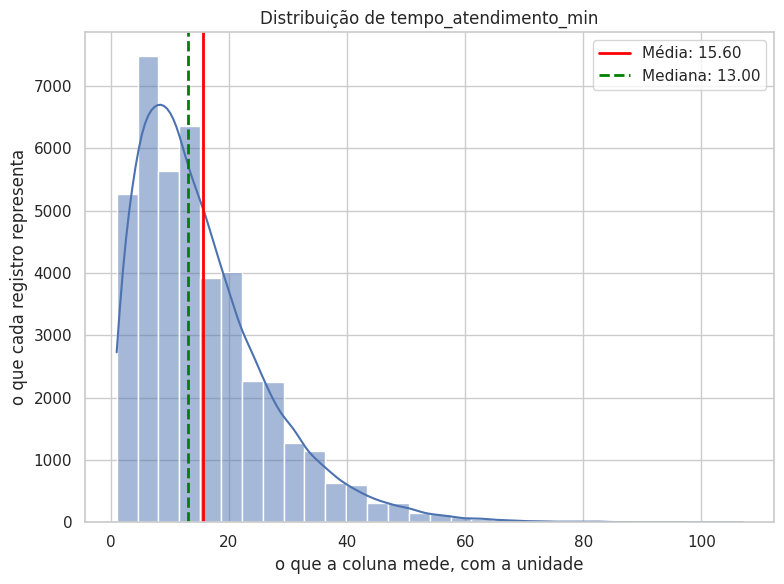

In [ ]:
# Histograma: como os valores se distribuem, com a curva da distribuição e as linhas de média e mediana.
sns.histplot(serie_numerica.dropna(), bins=30, kde=True)
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.axvline(serie_numerica.median(), color="green", linestyle="--", linewidth=2, label=f"Mediana: {serie_numerica.median():.2f}")
plt.title(f"Distribuição de {COLUNA_NUMERICA}")
plt.xlabel("o que a coluna mede, com a unidade")        # lacuna: nome do eixo x, em linguagem simples
plt.ylabel("o que cada registro representa")            # lacuna: nome do eixo y, em linguagem simples
plt.legend()
plt.tight_layout()
plt.show()

Célula 20 · Boxplot

O que esta célula faz: desenha o boxplot: a caixa é a faixa central (25% a 75%) e os pontos fora são candidatos a outlier. A linha vermelha marca a média.

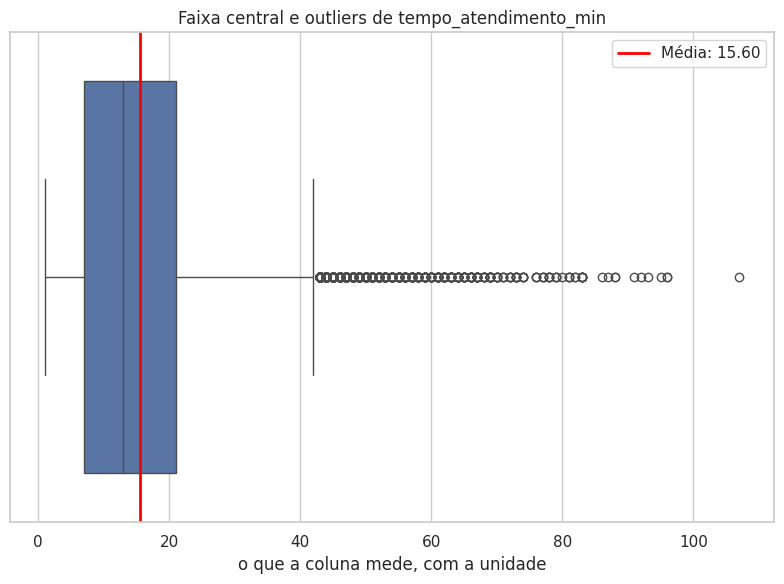

In [ ]:
# Boxplot: a caixa é a faixa central (25% a 75%); os pontos fora são candidatos a outlier.
sns.boxplot(x=serie_numerica.dropna())
plt.axvline(serie_numerica.mean(), color="red", linestyle="-", linewidth=2, label=f"Média: {serie_numerica.mean():.2f}")
plt.title(f"Faixa central e outliers de {COLUNA_NUMERICA}")
plt.xlabel("o que a coluna mede, com a unidade")        # lacuna: nome do eixo x, em linguagem simples
plt.legend()
plt.tight_layout()
plt.show()

Escreva, abaixo dos gráficos, uma frase dizendo o que eles mostram e qual insight eles ilustram. Gráfico sem frase de leitura não conta como análise.

```markdown
**Análise Visual e Insights dos Gráficos**

- **O que os gráficos mostram:**
  - **Histograma (Distribuição):** Mostra que a grande maioria dos chamados é resolvida rapidamente, concentrando-se na parte esquerda do gráfico (entre 1 e 30 minutos). A curva decai suavemente à medida que o tempo aumenta, com a linha vermelha da **média (15.60 min)** sendo puxada para a direita em relação à linha verde tracejada da **mediana (13.00 min)**.
  - **Boxplot (Dispersão e Outliers):** A caixa central azul representa onde estão 50% dos dados (entre 7 e 21 minutos, correspondendo ao primeiro e terceiro quartil). A linha vermelha indica a média. Os diversos pontos isolados à direita do limite de 42 minutos confirmam visualmente a presença de uma cauda longa de valores atípicos (outliers), que se estendem até o tempo máximo de 107 minutos.

- **Insights operacionais ilustrados:**
  - A assimetria à direita comprova que o processo de atendimento é eficiente para a maior parte dos clientes, mas sofre com uma falta de padronização ou gargalos específicos em cerca de 3% dos casos (os 1.247 chamados considerados outliers).
  - Como a mediana real está em 13 minutos, os casos que ultrapassam os 42 minutos distorcem a percepção média do serviço, indicando que a equipe de suporte lida com duas realidades distintas: soluções rápidas do dia a dia e incidentes complexos altamente demorados que necessitam de fluxos de escalonamento mais bem definidos.

# Generated-by: AI (Gemini)
# AI-Generated-Date: 2025-02-14
# SPDX-SnippetCopyrightText: AI-Assisted Code
# SPDX-License-Identifier: MIT
```

Registrar o uso de IA
Revise o notebook inteiro. Acima de cada trecho gerado ou ajustado com apoio de IA, inclua o registro, informando a ferramenta e a data:

# Generated-by: AI (Gemini / GPT-4 / Claude)
# AI-Generated-Date: AAAA-MM-DD
# SPDX-SnippetCopyrightText: AI-Assisted Code
# SPDX-License-Identifier: MIT
Se um insight ou uma recomendação foi redigido com apoio de IA, registre. Se nenhum trecho usou IA, não há o que registrar.
Números e conclusões sugeridos por IA devem ser verificados no seu notebook, nunca copiados como fato.


Entregar no Canvas
O relatório é o próprio notebook. A entrega é o link do repositório no GitHub com ele.

Releia o notebook de cima para baixo: ele deve ter a pergunta de negócio (Passo 1), as tabelas e frases de insight, a decisão sobre outliers e ausentes (Passo 8) e a recomendação (Passo 10).
Reinicie e execute tudo, para confirmar que não há erro: Ambiente de execução → Reiniciar sessão e executar tudo.
No Colab, salve o notebook no repositório do Desafio 1 (projeto_desafios_tecnicos_ad): Arquivo → Salvar uma cópia no GitHub.
Confira a lista final abaixo.
Entregue no Canvas o link do repositório do GitHub.